"""
This is a multi-class model
I am supposed to predict resistance to 9 antibiotics and 8 antibiotic classes ( wish me luck)
"""

In [1]:
# ============================================
# STEP 1: IMPORT LIBRARIES
# ============================================

# Data manipulation
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning - Base Models
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Multi-Label Wrappers
from sklearn.multioutput import MultiOutputClassifier, ClassifierChain

# Cross-Validation
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, hamming_loss, jaccard_score
)

# Imbalance Handling
from sklearn.utils.class_weight import compute_class_weight

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


In [2]:
# ============================================
# STEP 2: LOAD DATASET
# ============================================

# Load data
filepath = "dataset_antibiotic_model.csv"
df = pd.read_csv(filepath)

print(f"Dataset Shape: {df.shape}")
print(f"  - Total samples: {df.shape[0]}")
print(f"  - Total columns: {df.shape[1]}")
print("\nFirst 3 rows:")
print(df.head(3))

Dataset Shape: (398, 9019)
  - Total samples: 398
  - Total columns: 9019

First 3 rows:
   Genome_ID  ampicillin  chloramphenicol  nalidixic acid  pefloxacin  \
0    595.811           0                0               0           0   
1    595.812           0                0               0           0   
2    595.860           0                0               0           0   

   streptomycin  sulfamethoxazole  sulfisoxazole  trimethoprim  \
0             0                 1              0             0   
1             0                 0              0             0   
2             0                 0              0             0   

   trimethoprim/sulfamethoxazole  ...  HKFYPAFIHI  LMAAKAKNGV  PVLLSVSRKS  \
0                              0  ...           0           0           0   
1                              0  ...           0           0           0   
2                              0  ...           0           0           0   

   GLKPIEDIAD  ALKADGIPVS  PSALLPIRDR  VQNRV

In [3]:
# ============================================
# STEP 3: DEFINE LABEL COLUMNS
# ============================================

# Define antibiotic resistance labels (your 9 antibiotics)
ANTIBIOTIC_LABELS = [
    'ampicillin',
    'chloramphenicol', 
    'nalidixic acid',
    'pefloxacin',
    'streptomycin',
    'sulfamethoxazole',
    'sulfisoxazole',
    'trimethoprim',
    'trimethoprim/sulfamethoxazole'
]

# Verify all labels exist in dataset
missing_labels = [label for label in ANTIBIOTIC_LABELS if label not in df.columns]
if missing_labels:
    print(f"❌ ERROR: Missing labels in dataset: {missing_labels}")
else:
    print(f"✓ All {len(ANTIBIOTIC_LABELS)} antibiotic labels found in dataset")

# Separate features (X) and labels (y)
X = df.drop(columns=['Genome_ID'] + ANTIBIOTIC_LABELS)
y = df[ANTIBIOTIC_LABELS]

print(f"\n✓ Features (X): {X.shape}")
print(f"✓ Labels (y): {y.shape}")


✓ All 9 antibiotic labels found in dataset

✓ Features (X): (398, 9009)
✓ Labels (y): (398, 9)


In [4]:
# ============================================
# STEP 4: CHECK CLASS BALANCE
# ============================================

print("\n" + "="*60)
print("CLASS DISTRIBUTION (Resistant vs Susceptible)")
print("="*60)

balance_report = []

for antibiotic in ANTIBIOTIC_LABELS:
    susceptible = (y[antibiotic] == 0).sum()
    resistant = (y[antibiotic] == 1).sum()
    total = len(y)
    
    balance_report.append({
        'Antibiotic': antibiotic,
        'Susceptible (0)': susceptible,
        'Resistant (1)': resistant,
        'Total': total,
        '% Resistant': f"{(resistant/total)*100:.1f}%"
    })
    
    print(f"\n{antibiotic}:")
    print(f"  Susceptible: {susceptible} ({(susceptible/total)*100:.1f}%)")
    print(f"  Resistant:   {resistant} ({(resistant/total)*100:.1f}%)")

# Convert to DataFrame for easy viewing
balance_df = pd.DataFrame(balance_report)
print("\n" + "="*60)
print(balance_df.to_string(index=False))
print("="*60)



CLASS DISTRIBUTION (Resistant vs Susceptible)

ampicillin:
  Susceptible: 231 (58.0%)
  Resistant:   167 (42.0%)

chloramphenicol:
  Susceptible: 241 (60.6%)
  Resistant:   157 (39.4%)

nalidixic acid:
  Susceptible: 292 (73.4%)
  Resistant:   106 (26.6%)

pefloxacin:
  Susceptible: 295 (74.1%)
  Resistant:   103 (25.9%)

streptomycin:
  Susceptible: 228 (57.3%)
  Resistant:   170 (42.7%)

sulfamethoxazole:
  Susceptible: 237 (59.5%)
  Resistant:   161 (40.5%)

sulfisoxazole:
  Susceptible: 227 (57.0%)
  Resistant:   171 (43.0%)

trimethoprim:
  Susceptible: 211 (53.0%)
  Resistant:   187 (47.0%)

trimethoprim/sulfamethoxazole:
  Susceptible: 237 (59.5%)
  Resistant:   161 (40.5%)

                   Antibiotic  Susceptible (0)  Resistant (1)  Total % Resistant
                   ampicillin              231            167    398       42.0%
              chloramphenicol              241            157    398       39.4%
               nalidixic acid              292            106    

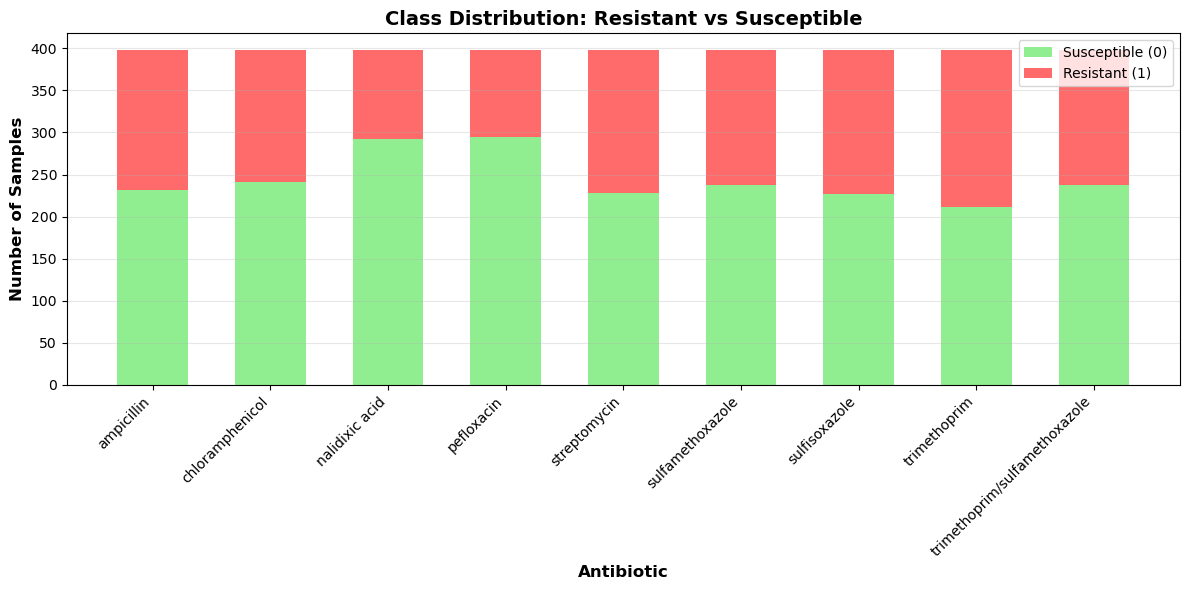

✓ Class distribution visualized


In [5]:
# ============================================
# STEP 5: VISUALIZE CLASS BALANCE
# ============================================

fig, ax = plt.subplots(figsize=(12, 6))

# Prepare data for plotting
antibiotics = []
resistant_counts = []
susceptible_counts = []

for antibiotic in ANTIBIOTIC_LABELS:
    antibiotics.append(antibiotic)
    resistant_counts.append((y[antibiotic] == 1).sum())
    susceptible_counts.append((y[antibiotic] == 0).sum())

# Create stacked bar chart
x = np.arange(len(antibiotics))
width = 0.6

p1 = ax.bar(x, susceptible_counts, width, label='Susceptible (0)', color='#90EE90')
p2 = ax.bar(x, resistant_counts, width, bottom=susceptible_counts, 
            label='Resistant (1)', color='#FF6B6B')

ax.set_xlabel('Antibiotic', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Samples', fontsize=12, fontweight='bold')
ax.set_title('Class Distribution: Resistant vs Susceptible', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(antibiotics, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ Class distribution visualized")

In [6]:
# ============================================
# STEP 6: DEFINE BASE MODELS
# ============================================

def get_models(use_balancing=False):
    """
    Returns dictionary of ML models for multi-label classification.
    
    Parameters:
    -----------
    use_balancing : bool
        If True, applies class weight balancing to handle imbalance
        
    Returns:
    --------
    dict : Dictionary of model_name -> model_object
    """
    
    if use_balancing:
        print("🔧 Creating BALANCED models (with class weights)")
        
        models = {
            'XGBoost': XGBClassifier(
                n_estimators=100,
                max_depth=5,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=RANDOM_STATE,
                eval_metric='logloss',
                use_label_encoder=False,
                n_jobs=-1
                # Note: scale_pos_weight will be set per-label by MultiOutputClassifier
            ),
            
            'Random Forest': RandomForestClassifier(
                n_estimators=100,
                max_depth=10,
                min_samples_split=5,
                min_samples_leaf=2,
                class_weight='balanced',  # Automatic balancing
                random_state=RANDOM_STATE,
                n_jobs=-1
            ),
            
            'Extra Trees': ExtraTreesClassifier(
                n_estimators=100,
                max_depth=10,
                min_samples_split=5,
                min_samples_leaf=2,
                class_weight='balanced',  # Automatic balancing
                random_state=RANDOM_STATE,
                n_jobs=-1
            ),
            
            'Gradient Boosting': GradientBoostingClassifier(
                n_estimators=100,
                max_depth=5,
                learning_rate=0.1,
                subsample=0.8,
                random_state=RANDOM_STATE
                # Note: GB doesn't have class_weight parameter
                # Alternative: use sample_weight during fit
            )
        }
        
    else:
        print("🔧 Creating UNBALANCED models (no class weights)")
        
        models = {
            'XGBoost': XGBClassifier(
                n_estimators=100,
                max_depth=5,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=RANDOM_STATE,
                eval_metric='logloss',
                use_label_encoder=False,
                n_jobs=-1
            ),
            
            'Random Forest': RandomForestClassifier(
                n_estimators=100,
                max_depth=10,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ),
            
            'Extra Trees': ExtraTreesClassifier(
                n_estimators=100,
                max_depth=10,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ),
            
            'Gradient Boosting': GradientBoostingClassifier(
                n_estimators=100,
                max_depth=5,
                learning_rate=0.1,
                subsample=0.8,
                random_state=RANDOM_STATE
            )
        }
    
    return models

# Test function
print("\nTesting model creation:")
models_unbalanced = get_models(use_balancing=False)
models_balanced = get_models(use_balancing=True)

print(f"\n✓ Created {len(models_unbalanced)} unbalanced models")
print(f"✓ Created {len(models_balanced)} balanced models")


Testing model creation:
🔧 Creating UNBALANCED models (no class weights)
🔧 Creating BALANCED models (with class weights)

✓ Created 4 unbalanced models
✓ Created 4 balanced models


In [7]:
# ============================================
# STEP 7: DEFINE MULTI-LABEL STRATEGIES
# ============================================

def create_multilabel_model(base_model, strategy='binary_relevance'):
    """
    Wraps a base classifier for multi-label classification.
    
    Parameters:
    -----------
    base_model : sklearn estimator
        Base classifier (e.g., XGBoost, Random Forest)
        
    strategy : str
        'binary_relevance' -> MultiOutputClassifier (independent labels)
        'classifier_chain' -> ClassifierChain (capture dependencies)
        
    Returns:
    --------
    Wrapped multi-label classifier
    """
    
    if strategy == 'binary_relevance':
        # Each antibiotic predicted independently
        return MultiOutputClassifier(base_model, n_jobs=-1)
    
    elif strategy == 'classifier_chain':
        # Predictions chained: antibiotic1 → antibiotic2 → antibiotic3 ...
        return ClassifierChain(base_model, order='random', random_state=RANDOM_STATE)
    
    else:
        raise ValueError(f"Unknown strategy: {strategy}")

# Test
print("\nTesting multi-label wrappers:")
test_model = XGBClassifier(random_state=RANDOM_STATE, use_label_encoder=False)

ml_binary = create_multilabel_model(test_model, strategy='binary_relevance')
ml_chain = create_multilabel_model(test_model, strategy='classifier_chain')

print(f"✓ Binary Relevance wrapper: {type(ml_binary).__name__}")
print(f"✓ Classifier Chain wrapper: {type(ml_chain).__name__}")


Testing multi-label wrappers:
✓ Binary Relevance wrapper: MultiOutputClassifier
✓ Classifier Chain wrapper: ClassifierChain


In [8]:
# ============================================
# STEP 8: DEFINE MULTI-LABEL METRICS
# ============================================

def calculate_multilabel_metrics(y_true, y_pred):
    """
    Calculate comprehensive metrics for multi-label classification.
    
    Parameters:
    -----------
    y_true : array-like, shape (n_samples, n_labels)
        True binary labels
        
    y_pred : array-like, shape (n_samples, n_labels)
        Predicted binary labels
        
    Returns:
    --------
    dict : Metrics averaged across all labels
    """
    
    metrics = {
        # Overall metrics (across all antibiotics)
        'hamming_loss': hamming_loss(y_true, y_pred),  # Lower is better
        'exact_match': accuracy_score(y_true, y_pred),  # All labels correct
        'jaccard': jaccard_score(y_true, y_pred, average='samples'),  # Similarity
        
        # Per-label metrics (averaged)
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_micro': f1_score(y_true, y_pred, average='micro', zero_division=0),
    }
    
    return metrics


def calculate_per_antibiotic_metrics(y_true, y_pred, antibiotic_names):
    """
    Calculate F1-score for each antibiotic individually.
    
    Returns:
    --------
    dict : {antibiotic_name: f1_score}
    """
    
    per_label_f1 = {}
    
    for i, antibiotic in enumerate(antibiotic_names):
        f1 = f1_score(y_true[:, i], y_pred[:, i], zero_division=0)
        per_label_f1[antibiotic] = f1
    
    return per_label_f1


print("✓ Multi-label metric functions defined")
print("\nMetrics we'll track:")
print("  - Hamming Loss (% of wrong labels)")
print("  - Exact Match (% where ALL antibiotics correct)")
print("  - Jaccard Score (set similarity)")
print("  - Precision/Recall/F1 (per antibiotic, then averaged)")

✓ Multi-label metric functions defined

Metrics we'll track:
  - Hamming Loss (% of wrong labels)
  - Exact Match (% where ALL antibiotics correct)
  - Jaccard Score (set similarity)
  - Precision/Recall/F1 (per antibiotic, then averaged)


In [9]:
# ============================================
# STEP 9: CROSS-VALIDATION FOR MULTI-LABEL
# ============================================

from sklearn.model_selection import KFold

def evaluate_multilabel_cv(X, y, model, antibiotic_names, n_folds=6):
    """
    Perform K-fold cross-validation for multi-label classification.
    
    Parameters:
    -----------
    X : DataFrame, shape (n_samples, n_features)
        Feature matrix
        
    y : DataFrame, shape (n_samples, n_labels)
        Multi-label target matrix
        
    model : estimator
        Multi-label classifier (already wrapped)
        
    antibiotic_names : list
        Names of antibiotics (for per-label metrics)
        
    n_folds : int
        Number of cross-validation folds
        
    Returns:
    --------
    dict : Cross-validated metrics
    """
    
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    
    # Storage for metrics across folds
    fold_metrics = []
    fold_per_antibiotic = {ab: [] for ab in antibiotic_names}
    
    print(f"\n  Running {n_folds}-fold cross-validation...")
    
    for fold, (train_idx, val_idx) in enumerate(kf.split(X), 1):
        # Split data
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        # Train
        model.fit(X_train, y_train)
        
        # Predict
        y_pred = model.predict(X_val)
        
        # Calculate overall metrics
        metrics = calculate_multilabel_metrics(y_val.values, y_pred)
        fold_metrics.append(metrics)
        
        # Calculate per-antibiotic F1
        per_ab = calculate_per_antibiotic_metrics(
            y_val.values, y_pred, antibiotic_names
        )
        for ab, f1 in per_ab.items():
            fold_per_antibiotic[ab].append(f1)
        
        print(f"    Fold {fold}/{n_folds} - F1 Macro: {metrics['f1_macro']:.3f}")
    
    # Average metrics across folds
    avg_metrics = {
        metric: np.mean([fold[metric] for fold in fold_metrics])
        for metric in fold_metrics[0].keys()
    }
    
    # Average per-antibiotic F1
    avg_per_antibiotic = {
        ab: np.mean(scores) for ab, scores in fold_per_antibiotic.items()
    }
    
    return avg_metrics, avg_per_antibiotic


print("✓ Cross-validation function defined")

✓ Cross-validation function defined


In [10]:
# ============================================
# STEP 10: TRAIN AND COMPARE ALL MODELS
# ============================================

# Storage for results
results = []

# Define experiment configurations
strategies = ['binary_relevance', 'classifier_chain']
balancing_settings = [False, True]

print("\n" + "="*70)
print("STARTING MODEL TRAINING AND COMPARISON")
print("="*70)

for use_balancing in balancing_settings:
    
    balance_label = "BALANCED" if use_balancing else "UNBALANCED"
    print(f"\n{'='*70}")
    print(f"EXPERIMENT: {balance_label} MODELS")
    print(f"{'='*70}")
    
    # Get models
    models = get_models(use_balancing=use_balancing)
    
    for strategy in strategies:
        
        print(f"\n📊 Strategy: {strategy.upper()}")
        print("-" * 70)
        
        for model_name, base_model in models.items():
            
            print(f"\n🔬 Training: {model_name}")
            
            # Wrap model for multi-label
            ml_model = create_multilabel_model(base_model, strategy=strategy)
            
            # Cross-validate
            avg_metrics, per_antibiotic_f1 = evaluate_multilabel_cv(
                X, y, ml_model, ANTIBIOTIC_LABELS, n_folds=6
            )
            
            # Store results
            result = {
                'Model': model_name,
                'Strategy': strategy,
                'Balanced': balance_label,
                **avg_metrics,  # Unpack all metrics
                'Per_Antibiotic_F1': per_antibiotic_f1
            }
            results.append(result)
            
            # Print summary
            print(f"\n  ✓ Results:")
            print(f"    F1 Macro:     {avg_metrics['f1_macro']:.3f}")
            print(f"    F1 Micro:     {avg_metrics['f1_micro']:.3f}")
            print(f"    Exact Match:  {avg_metrics['exact_match']:.3f}")
            print(f"    Hamming Loss: {avg_metrics['hamming_loss']:.3f}")

print("\n" + "="*70)
print("✓ ALL MODELS TRAINED")
print("="*70)


STARTING MODEL TRAINING AND COMPARISON

EXPERIMENT: UNBALANCED MODELS
🔧 Creating UNBALANCED models (no class weights)

📊 Strategy: BINARY_RELEVANCE
----------------------------------------------------------------------

🔬 Training: XGBoost

  Running 6-fold cross-validation...
    Fold 1/6 - F1 Macro: 0.956
    Fold 2/6 - F1 Macro: 0.976
    Fold 3/6 - F1 Macro: 0.913
    Fold 4/6 - F1 Macro: 0.923
    Fold 5/6 - F1 Macro: 0.934
    Fold 6/6 - F1 Macro: 0.944

  ✓ Results:
    F1 Macro:     0.941
    F1 Micro:     0.943
    Exact Match:  0.872
    Hamming Loss: 0.041

🔬 Training: Random Forest

  Running 6-fold cross-validation...
    Fold 1/6 - F1 Macro: 0.870
    Fold 2/6 - F1 Macro: 0.904
    Fold 3/6 - F1 Macro: 0.854
    Fold 4/6 - F1 Macro: 0.885
    Fold 5/6 - F1 Macro: 0.899
    Fold 6/6 - F1 Macro: 0.886

  ✓ Results:
    F1 Macro:     0.883
    F1 Micro:     0.900
    Exact Match:  0.776
    Hamming Loss: 0.072

🔬 Training: Extra Trees

  Running 6-fold cross-validation...
 

In [11]:
# ============================================
# STEP 11: COMPARE RESULTS
# ============================================

# Convert results to DataFrame
results_df = pd.DataFrame(results)

# Sort by F1 Macro (primary metric for multi-label)
results_df = results_df.sort_values('f1_macro', ascending=False)

print("\n" + "="*90)
print("FINAL RESULTS - RANKED BY F1 MACRO")
print("="*90)

# Display main metrics
display_cols = ['Model', 'Strategy', 'Balanced', 'f1_macro', 'f1_micro', 
                'exact_match', 'hamming_loss', 'precision', 'recall']

print(results_df[display_cols].to_string(index=False))

# Identify best model
best_model = results_df.iloc[0]
print("\n" + "="*90)
print("🏆 BEST MODEL")
print("="*90)
print(f"Model:          {best_model['Model']}")
print(f"Strategy:       {best_model['Strategy']}")
print(f"Balancing:      {best_model['Balanced']}")
print(f"F1 Macro:       {best_model['f1_macro']:.4f}")
print(f"F1 Micro:       {best_model['f1_micro']:.4f}")
print(f"Exact Match:    {best_model['exact_match']:.4f}")
print(f"Hamming Loss:   {best_model['hamming_loss']:.4f}")


FINAL RESULTS - RANKED BY F1 MACRO
            Model         Strategy   Balanced  f1_macro  f1_micro  exact_match  hamming_loss  precision   recall
          XGBoost binary_relevance UNBALANCED  0.940941  0.942790     0.871740      0.040835   0.972962 0.913135
          XGBoost binary_relevance   BALANCED  0.940941  0.942790     0.871740      0.040835   0.972962 0.913135
Gradient Boosting binary_relevance UNBALANCED  0.939564  0.940658     0.871740      0.042494   0.969365 0.914474
Gradient Boosting binary_relevance   BALANCED  0.939564  0.940658     0.871740      0.042494   0.969365 0.914474
Gradient Boosting classifier_chain UNBALANCED  0.935921  0.937263     0.866765      0.045287   0.962936 0.913078
Gradient Boosting classifier_chain   BALANCED  0.935921  0.937263     0.866765      0.045287   0.962936 0.913078
          XGBoost classifier_chain UNBALANCED  0.935527  0.938073     0.871740      0.044186   0.962807 0.912003
          XGBoost classifier_chain   BALANCED  0.935527  0.9


PER-ANTIBIOTIC F1 SCORES (Best Model: XGBoost - binary_relevance)
chloramphenicol                     → F1: 0.957
streptomycin                        → F1: 0.952
sulfisoxazole                       → F1: 0.951
trimethoprim/sulfamethoxazole       → F1: 0.949
trimethoprim                        → F1: 0.939
ampicillin                          → F1: 0.938
pefloxacin                          → F1: 0.935
sulfamethoxazole                    → F1: 0.929
nalidixic acid                      → F1: 0.919


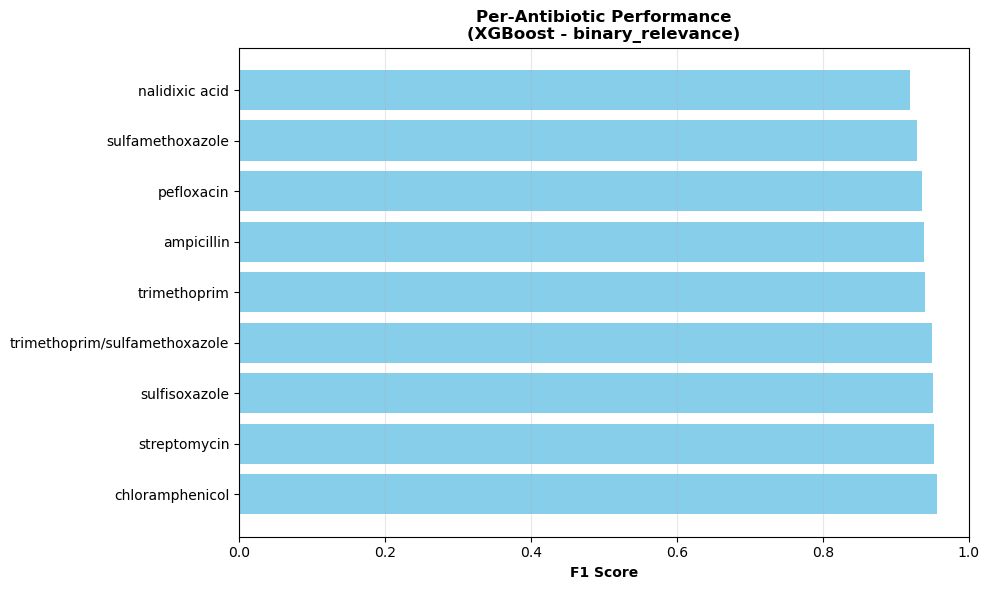

In [12]:
# ============================================
# STEP 12: PER-ANTIBIOTIC BREAKDOWN (BEST MODEL)
# ============================================

print("\n" + "="*90)
print(f"PER-ANTIBIOTIC F1 SCORES (Best Model: {best_model['Model']} - {best_model['Strategy']})")
print("="*90)

per_ab_scores = best_model['Per_Antibiotic_F1']

# Sort by F1 score
sorted_antibiotics = sorted(per_ab_scores.items(), key=lambda x: x[1], reverse=True)

for antibiotic, f1 in sorted_antibiotics:
    print(f"{antibiotic:35s} → F1: {f1:.3f}")

# Visualize
fig, ax = plt.subplots(figsize=(10, 6))
antibiotics = [ab for ab, _ in sorted_antibiotics]
f1_scores = [f1 for _, f1 in sorted_antibiotics]

ax.barh(antibiotics, f1_scores, color='skyblue')
ax.set_xlabel('F1 Score', fontweight='bold')
ax.set_title(f'Per-Antibiotic Performance\n({best_model["Model"]} - {best_model["Strategy"]})', 
             fontweight='bold')
ax.set_xlim([0, 1])
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
import pandas as pd

ANTIBIOTIC_LABELS = [
    'ampicillin',
    'chloramphenicol', 
    'nalidixic acid',
    'pefloxacin',
    'streptomycin',
    'sulfamethoxazole',
    'sulfisoxazole',
    'trimethoprim',
    'trimethoprim/sulfamethoxazole'
]
df_pefox = pd.read_csv("dataset_antibiotic_model.csv")
features_pefox = [col for col in df_pefox.columns if col not in (['Genome_ID'] + ANTIBIOTIC_LABELS)]
with open('antibiotic_features.txt', 'w') as f:
    for feat in features_pefox:
        f.write(feat + '\n')
print(f"Antibiotics: {len(features_pefox)} features")



ANTIBIOTIC_CLASS = [ 'Aminoglycosides', 
'Amphenicols', 
'Beta-lactams',
'Dihydrofolate reductase inhibitors', 
'Fluoroquinolones', 
'Quinolones',
'Sulfonamide combination', 
'Sulfonamides']

df_trim = pd.read_csv("dataset_class_model.csv")
features_trim = [col for col in df_trim.columns if col not in (['Genome_ID']+ ANTIBIOTIC_CLASS)]
with open('antibiotic_class_features.txt', 'w') as f:
    for feat in features_trim:
        f.write(feat + '\n')
print(f"Class: {len(features_trim)} features")



Antibiotics: 9009 features
Class: 9009 features
